# CLIP で画像と日本語の文を同じ空間に埋め込み、検索・分類する

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/32_vision_language/clip_ja.ipynb)

NLP クックブック 32-01 ／ 画像と言語

画像とテキストを同じベクトル空間に置いて、学習データなしに日本語のラベルで画像を分類したり、日本語の文で画像を検索したりしたい。

In [1]:
!pip install -q matplotlib-fontja

In [2]:
import io, re, time
import requests
from PIL import Image

# Wikimedia Commons の画像 (CC BY / CC BY-SA / FAL / パブリックドメイン。ファイルごとの作者・出典・ライセンスは下で表示する)
FILES = {
    "犬": ["Alaskan Malamute R Bartz.jpg", "Beagle sleeping in Hautmont (DSC07212).jpg",
           "Dalmatian fetching a stick.jpg", "2011-04-02 a Shiba Inu in Japan.jpg"],
    "猫": ["Cat sleeping in the Ngọc Sơn Temple in Hanoi, 20240204 1309 5747.jpg", "Golden tabby and white kitten n01.jpg",
           "Colossus the Cat 2.JPG", "Бишкек, кот в траве на Элебесова.jpg"],
    "鳥": ["Black-naped Monarch 0A2A8267.jpg", "Cedar waxwing in Green-Wood Cemetery (55650).jpg",
           "Grey-crowned Babblers 1605.jpg", "Sarcelle élégante DSCF2036.jpg"],
    "車": ["00 car, 40. ADAC Stormarn Rallye, Luetjensee (TR256763).jpg", "1939 Delage D6 Grand Prix, front right (Brooklyn).jpg",
           "18. ADAC Stormarn Classic, Zarpen (TR257255).jpg", "18. ADAC Stormarn Classic, Luetjensee (P1045457).jpg"],
    "電車": ["20160814 fomer JR train Yangon Circular Railway 0228.jpg", "Ankara asv2021-10 img75 Yenimahalle metro.jpg",
             "Coradia ZZe-03, Gare de l'Agha 2023.jpg", "Flirt, Susteren (LRM 20220311 101307).jpg"],
    "花": ["Abelmoschus sagittifolius 01.JPG", "Adenium obesum 02.JPG", "Alppiasteri 1.jpg", "Anthemis April 2010-1.jpg"],
    "ラーメン": ["2013.02.27.ramen.jpg", "Bikkuri-rahmen.jpg", "Butter Corn Ramen.JPG",
                 "Free-photo-of-a-bowl-of-ramen-with-eggs-and-meat.jpg"],
    "寿司": ["HSY- Sushi, Imitation Crab.jpg", "HSY- Sushi, Tai.jpg", "Nigiri Sushi (26505096851).jpg",
             "Nigirizushi at Luckiefun's Redi close up in April 2025.jpg"],
}
COUNT = ["2020-09-22 Shiba Inu running.jpg", "2020-09-22 two Shiba Inus 01.jpg", "2020-09-22 three Shiba Inus.jpg"]  # 柴犬が 1・2・3 匹

UA = {"User-Agent": "nlpcookbook-clip-recipe/0.1"}   # Wikimedia は User-Agent のないアクセスを拒否する

def commons_images(names, width=330):
    """Commons の API で縮小画像の URL・ファイルページの URL・ライセンス・作者を 1 回で取得し、画像を順にダウンロードする"""
    titles = ["File:" + n for n in names]
    r = requests.get("https://commons.wikimedia.org/w/api.php", headers=UA, timeout=30, params={
        "action": "query", "titles": "|".join(titles), "prop": "imageinfo", "iiprop": "url|extmetadata",
        "iiurlwidth": width, "format": "json", "formatversion": 2}).json()
    norm = {n["from"]: n["to"] for n in r["query"].get("normalized", [])}
    info = {p["title"]: p["imageinfo"][0] for p in r["query"]["pages"]}
    items = []
    for t in titles:
        ii = info[norm.get(t, t)]
        meta = ii["extmetadata"]
        img = Image.open(io.BytesIO(requests.get(ii["thumburl"], headers=UA, timeout=30).content)).convert("RGB")
        artist = re.sub(r"<[^>]+>", "", meta.get("Artist", {}).get("value", "")).strip().split("\n")[0]
        items.append({"title": t[5:], "image": img, "license": meta["LicenseShortName"]["value"], "artist": artist,
                      "url": ii["descriptionurl"]})
        time.sleep(0.2)
    return items

labels = list(FILES)
items = commons_images([n for ns in FILES.values() for n in ns] + COUNT)
data, count_items = items[:-3], items[-3:]
for it, y in zip(data, [y for y in labels for _ in FILES[y]]):
    it["label"] = y
for it in items:
    print(f"{it.get('label', '数')} | {it['artist']} | {it['license']} | {it['url']}")   # 作者・出典・ライセンス

犬 | Richard Bartz | CC BY-SA 2.5 | https://commons.wikimedia.org/wiki/File:Alaskan_Malamute_R_Bartz.jpg
犬 | Trougnouf (Benoit Brummer) | CC BY 4.0 | https://commons.wikimedia.org/wiki/File:Beagle_sleeping_in_Hautmont_(DSC07212).jpg
犬 | Lucasbosch | CC BY-SA 4.0 | https://commons.wikimedia.org/wiki/File:Dalmatian_fetching_a_stick.jpg
犬 | Alf Melin | CC BY-SA 2.0 | https://commons.wikimedia.org/wiki/File:2011-04-02_a_Shiba_Inu_in_Japan.jpg
猫 | Jakub Hałun | CC BY 4.0 | https://commons.wikimedia.org/wiki/File:Cat_sleeping_in_the_Ng%E1%BB%8Dc_S%C6%A1n_Temple_in_Hanoi,_20240204_1309_5747.jpg
猫 | Marie-Lan Nguyen | CC BY 2.5 | https://commons.wikimedia.org/wiki/File:Golden_tabby_and_white_kitten_n01.jpg
猫 | Collard | CC BY 3.0 | https://commons.wikimedia.org/wiki/File:Colossus_the_Cat_2.JPG
猫 | Nikolai Bulykin | CC BY-SA 4.0 | https://commons.wikimedia.org/wiki/File:%D0%91%D0%B8%D1%88%D0%BA%D0%B5%D0%BA,_%D0%BA%D0%BE%D1%82_%D0%B2_%D1%82%D1%80%D0%B0%D0%B2%D0%B5_%D0%BD%D0%B0_%D0%AD%D0%BB%D0%B5%

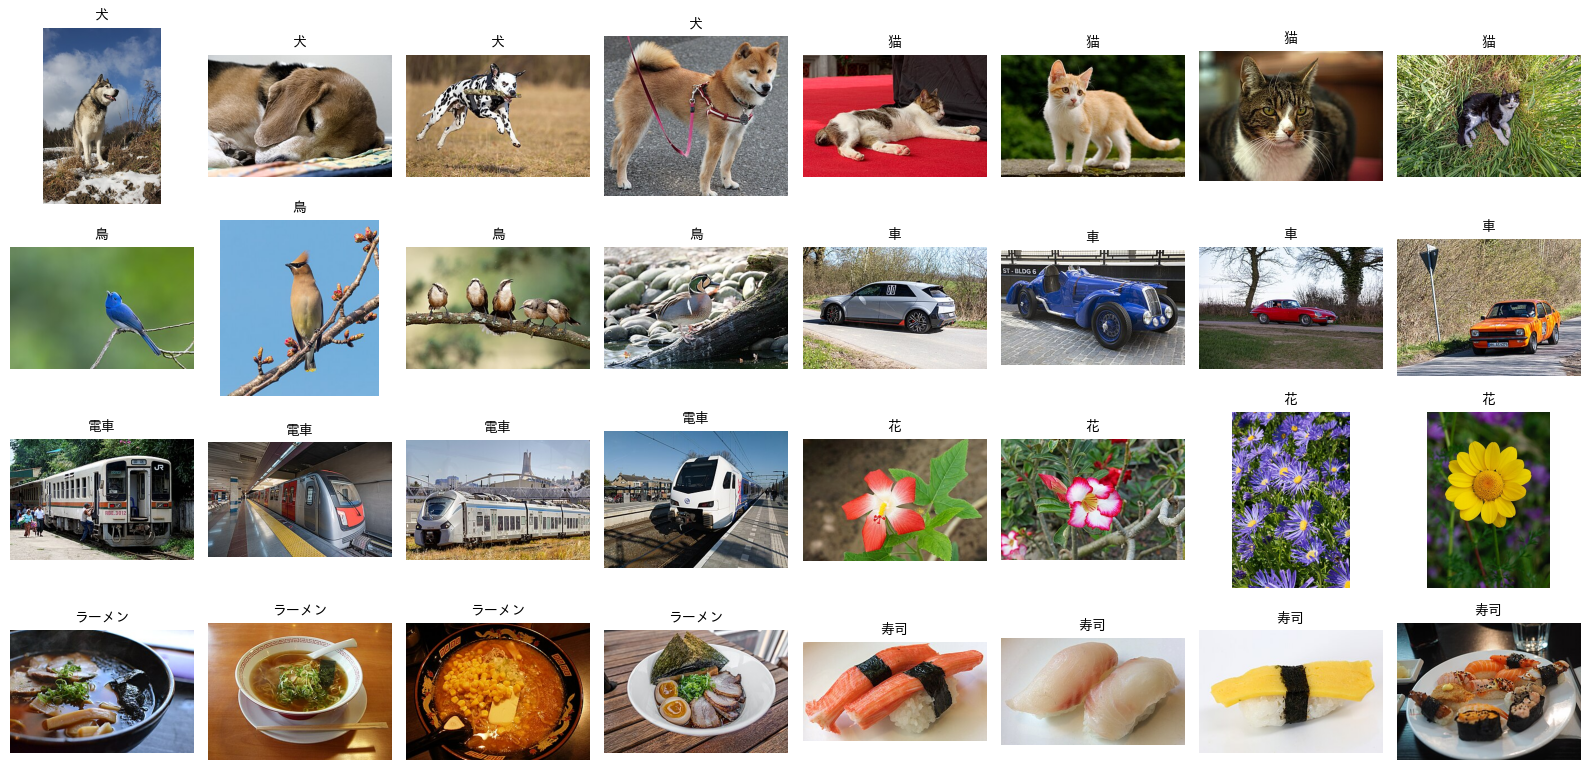

In [3]:
import matplotlib.pyplot as plt
import matplotlib_fontja

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for ax, it in zip(axes.flat, data):
    ax.imshow(it["image"]); ax.set_title(it["label"], fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

In [4]:
import torch
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from transformers import AutoConfig, AutoImageProcessor, AutoTokenizer
from transformers.dynamic_module_utils import get_class_from_dynamic_module

device = "cuda" if torch.cuda.is_available() else "cpu"
name = "line-corporation/clip-japanese-base"   # LY Corporation の日本語 CLIP (Apache-2.0)。画像側 Eva02-B、テキスト側 BERT
rev = "77a62f8af977acd73ec2f927fb73fdaeb13af7d1"      # リポジトリのコミットを固定する (中のコードを実行するので、すべての読み込みに渡す)
tokenizer = AutoTokenizer.from_pretrained(name, trust_remote_code=True, revision=rev)
processor = AutoImageProcessor.from_pretrained(name, trust_remote_code=True, revision=rev)
# モデルカードの AutoModel.from_pretrained(name, trust_remote_code=True) は transformers 5 系ではエラーになるので、
# リポジトリ内のクラスを取り出して重みを直接読み込む
CLYPModel = get_class_from_dynamic_module("modeling_clyp.CLYPModel", name, revision=rev)  # modeling_clyp.py を取得してクラスを返す
model = CLYPModel(AutoConfig.from_pretrained(name, trust_remote_code=True, revision=rev))  # config から重みが乱数のモデルを作る
print(model.load_state_dict(load_file(hf_hub_download(name, "model.safetensors", revision=rev))))  # All keys matched と出れば全部の重みが入った
model = model.to(device).eval()                      # 重みは float32 のまま使う (約 0.8GB で、T4 にも CPU にも載る)

@torch.no_grad()
def embed_images(images, batch_size=16):
    out = [model.get_image_features(**processor(images[i:i + batch_size], return_tensors="pt").to(device))
           for i in range(0, len(images), batch_size)]
    return F.normalize(torch.cat(out), dim=-1)     # 長さ 1 に正規化 → 内積 = コサイン類似度

@torch.no_grad()
def embed_texts(texts):
    return F.normalize(model.get_text_features(**tokenizer(texts).to(device)), dim=-1)

img_emb = embed_images([it["image"] for it in data])
temperature = model.itc_loss_fn.temperature.item()
print(img_emb.shape, "温度:", temperature)

<All keys matched successfully>
torch.Size([32, 512]) 温度: 0.010000637732446194


In [5]:
# (1) ゼロショット分類: ラベルを文にして埋め込み、画像に最も近い文のラベルを答えにする
gold = torch.tensor([labels.index(it["label"]) for it in data], device=device)
# 正解にならない紛らわしい候補も混ぜて、難しくした版も試す
distractors = ["オオカミ", "キツネ", "ウサギ", "バス", "トラック", "飛行機", "木", "うどん", "そば", "パスタ", "おにぎり", "刺身", "ケーキ"]
templates = ["{}", "{}の写真", "これは{}の写真です。", "{}が写っている画像", "{}のイラスト"]

def classify(templates, cands):
    # テンプレートが複数なら、ラベルごとに埋め込みを平均する (プロンプトのアンサンブル)
    t = torch.stack([embed_texts([tpl.format(y) for y in cands]) for tpl in templates]).mean(0)
    return img_emb @ F.normalize(t, dim=-1).T

for tpl in templates + [templates[:4]]:
    tpls = tpl if isinstance(tpl, list) else [tpl]
    sims = classify(tpls, labels)
    others = sims.masked_fill(F.one_hot(gold, len(labels)).bool(), -1).max(1).values
    margin = (sims[range(len(data)), gold] - others).mean()         # 正解ラベルと、次に近いラベルとの類似度の差
    sims2 = classify(tpls, labels + distractors)
    pred2 = sims2.argmax(1)
    wrong = [f"{it['title'][:20]}: {it['label']}→{(labels + distractors)[p]}" for it, p, g in zip(data, pred2.tolist(), gold.tolist()) if p != g]
    print(f"{' / '.join(tpls)[:42]:42} 8 択: 正解率 {(sims.argmax(1) == gold).float().mean():.3f} 差 {margin:.3f} | "
          f"21 択: 正解率 {(pred2 == gold).float().mean():.3f} 誤り {wrong}")

probs = (classify(["{}の写真"], labels) / temperature).softmax(1)   # 温度で割って softmax すると「確率」になる
print("1 枚目の画像:", {y: round(p, 3) for y, p in zip(labels, probs[0].tolist())})

{}                                         8 択: 正解率 1.000 差 0.102 | 21 択: 正解率 0.969 誤り ['Alaskan Malamute R B: 犬→オオカミ']
{}の写真                                      8 択: 正解率 1.000 差 0.106 | 21 択: 正解率 0.969 誤り ['Alaskan Malamute R B: 犬→オオカミ']
これは{}の写真です。                                8 択: 正解率 1.000 差 0.113 | 21 択: 正解率 0.938 誤り ['Alaskan Malamute R B: 犬→オオカミ', 'Nigiri Sushi (265050: 寿司→おにぎり']
{}が写っている画像                                 8 択: 正解率 1.000 差 0.109 | 21 択: 正解率 0.938 誤り ['Alaskan Malamute R B: 犬→オオカミ', 'Nigiri Sushi (265050: 寿司→おにぎり']
{}のイラスト                                    8 択: 正解率 1.000 差 0.108 | 21 択: 正解率 0.969 誤り ['Alaskan Malamute R B: 犬→オオカミ']
{} / {}の写真 / これは{}の写真です。 / {}が写っている画像      8 択: 正解率 1.000 差 0.117 | 21 択: 正解率 0.969 誤り ['Alaskan Malamute R B: 犬→オオカミ']
1 枚目の画像: {'犬': 1.0, '猫': 0.0, '鳥': 0.0, '車': 0.0, '電車': 0.0, '花': 0.0, 'ラーメン': 0.0, '寿司': 0.0}


In [6]:
# 細かい区別: 犬種 (柴犬・ビーグル・ダルメシアン・アラスカン・マラミュート) を、似た犬種も混ぜた候補から選ばせる
breeds = ["柴犬", "秋田犬", "ビーグル", "バセット・ハウンド", "ダルメシアン", "アラスカン・マラミュート", "シベリアン・ハスキー"]
dogs = [it for it in data if it["label"] == "犬"]
sims = img_emb[[data.index(d) for d in dogs]] @ embed_texts([f"{b}の写真" for b in breeds]).T
for d, row in zip(dogs, (sims / temperature).softmax(1)):
    top = row.topk(3)
    print(f"{d['title'][:35]:35}", "  ".join(f"{breeds[i]} {p:.2f}" for p, i in zip(top.values.tolist(), top.indices.tolist())))

Alaskan Malamute R Bartz.jpg        シベリアン・ハスキー 0.64  アラスカン・マラミュート 0.30  秋田犬 0.06
Beagle sleeping in Hautmont (DSC072 ビーグル 1.00  バセット・ハウンド 0.00  ダルメシアン 0.00
Dalmatian fetching a stick.jpg      ダルメシアン 1.00  ビーグル 0.00  バセット・ハウンド 0.00
2011-04-02 a Shiba Inu in Japan.jpg 柴犬 0.99  秋田犬 0.01  ビーグル 0.00


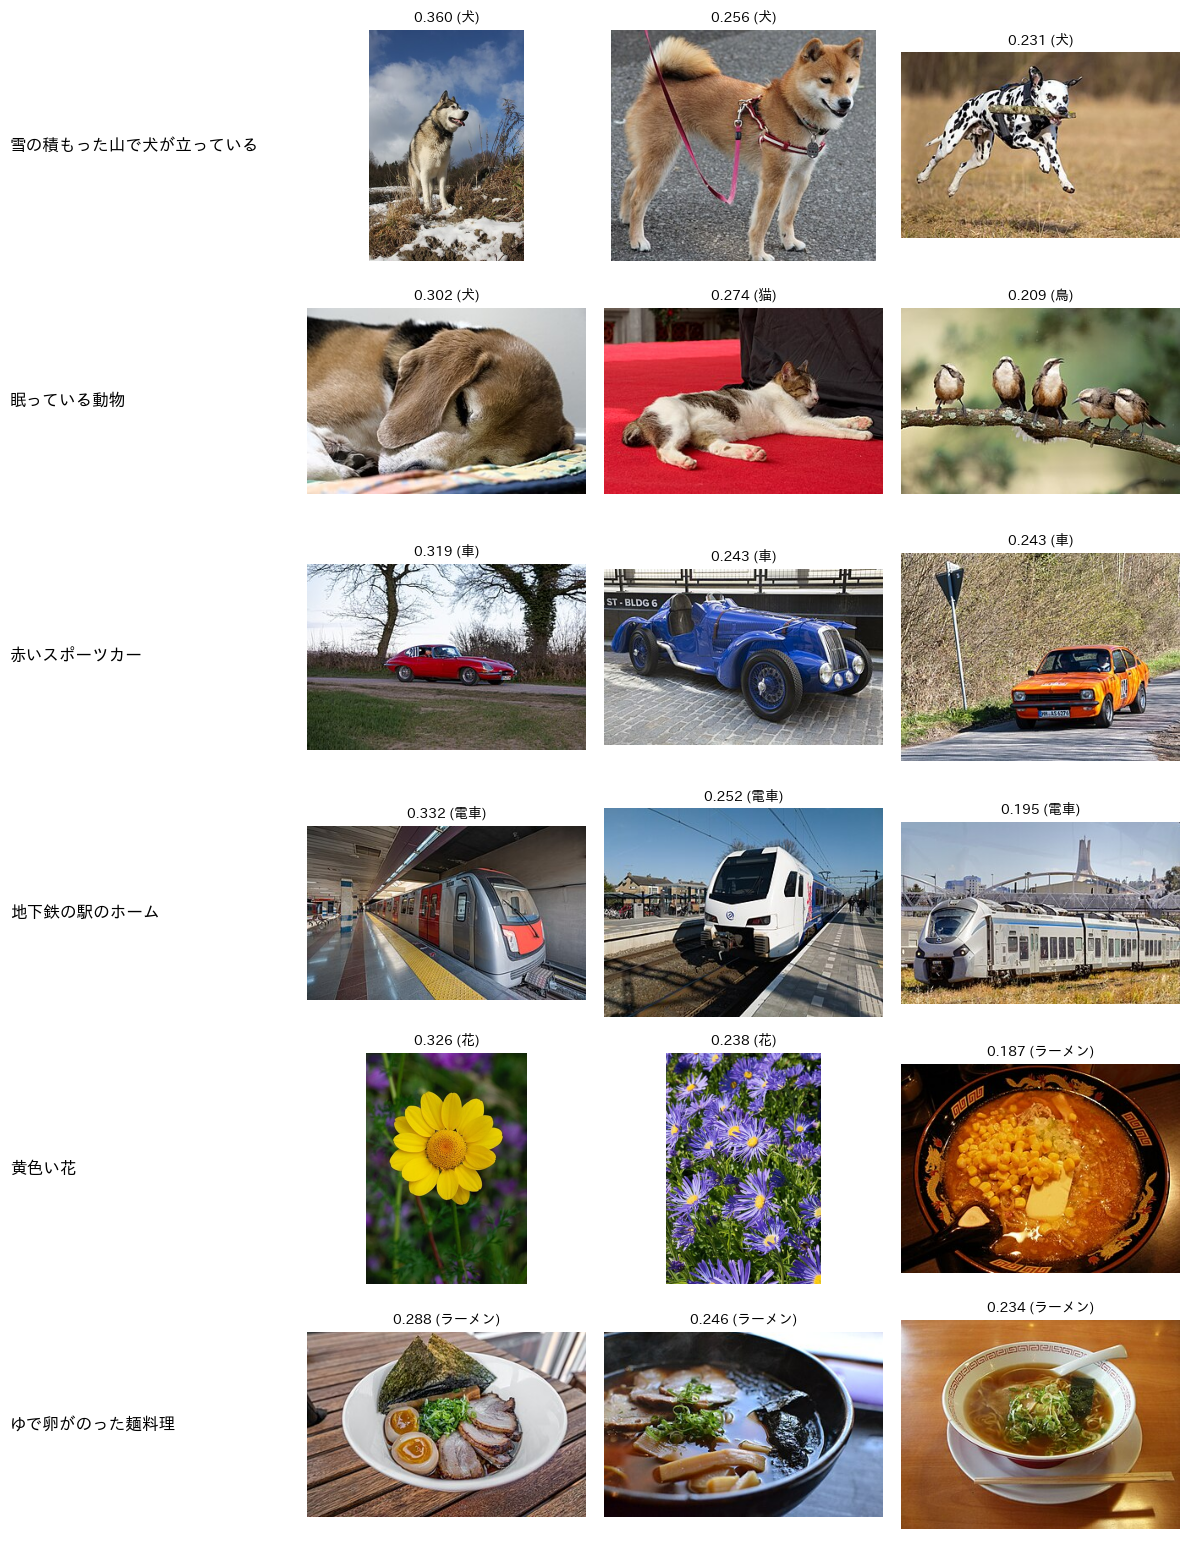

In [7]:
# (2) 日本語の文で画像を検索する: 文の埋め込みと全画像の埋め込みのコサイン類似度で並べる
queries = ["雪の積もった山で犬が立っている", "眠っている動物", "赤いスポーツカー", "地下鉄の駅のホーム", "黄色い花", "ゆで卵がのった麺料理"]
q_emb = embed_texts(queries)
sims = q_emb @ img_emb.T
fig, axes = plt.subplots(len(queries), 4, figsize=(12, 2.6 * len(queries)))
for row, q, s in zip(axes, queries, sims):
    top = s.topk(3)
    row[0].text(0, 0.5, q, fontsize=12, va="center"); row[0].axis("off")
    for ax, v, i in zip(row[1:], top.values.tolist(), top.indices.tolist()):
        ax.imshow(data[i]["image"]); ax.set_title(f"{v:.3f} ({data[i]['label']})", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

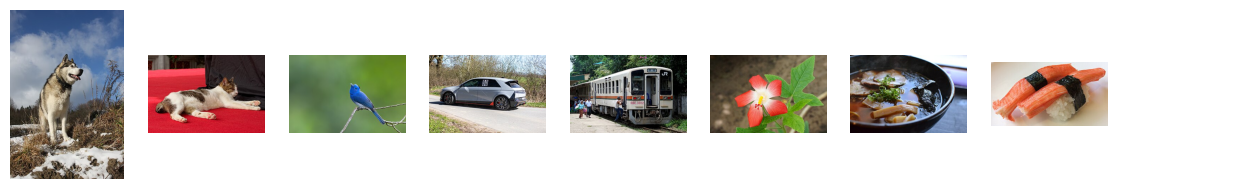

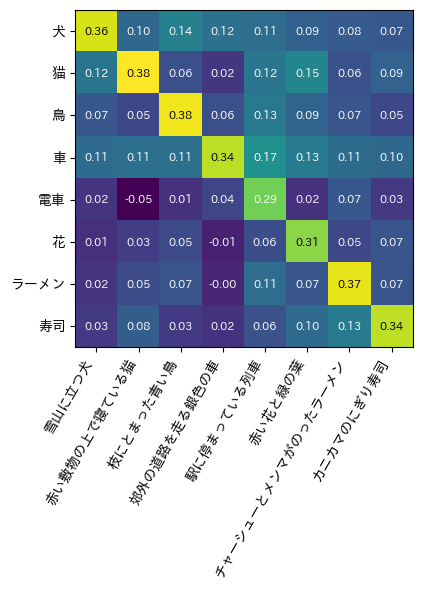

温度 1.0   損失 1.842  正しい組の確率 (画像→文) の平均 0.159
温度 0.1   損失 0.398  正しい組の確率 (画像→文) の平均 0.682
温度 0.010000637732446194 損失 0.000  正しい組の確率 (画像→文) の平均 1.000


In [8]:
# (3) 類似度行列: 8 枚の画像と、それぞれを説明する 8 つの文。対角線 (正しい組) が最も大きくなるように学習されている
idx = [labels.index(y) * 4 for y in labels]          # 各クラスの 1 枚目
captions = ["雪山に立つ犬", "赤い敷物の上で寝ている猫", "枝にとまった青い鳥", "郊外の道路を走る銀色の車",
            "駅に停まっている列車", "赤い花と緑の葉", "チャーシューとメンマがのったラーメン", "カニカマのにぎり寿司"]
S = img_emb[idx] @ embed_texts(captions).T          # 行: 画像、列: 文
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
for ax, i in zip(axes, idx):
    ax.imshow(data[i]["image"]); ax.axis("off")
axes[-1].axis("off")
plt.show()
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(S.cpu(), cmap="viridis")
ax.set_xticks(range(8), captions, rotation=60, ha="right"); ax.set_yticks(range(8), [data[i]["label"] for i in idx])
for r in range(8):
    for c in range(8):
        ax.text(c, r, f"{S[r, c]:.2f}", ha="center", va="center", color="white" if S[r, c] < S.max() * 0.8 else "black", fontsize=8)
plt.tight_layout(); plt.show()

# CLIP の学習の損失 (InfoNCE): 類似度を温度で割り、行 (画像→文) と列 (文→画像) の両方向でクロスエントロピーを取る。
# バッチ内の正しい組が正例、それ以外の組がすべて負例になる
target = torch.arange(8, device=device)
for t in [1.0, 0.1, temperature]:
    logits = S / t
    loss = (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target)) / 2
    print(f"温度 {t:<5} 損失 {loss:.3f}  正しい組の確率 (画像→文) の平均 {logits.softmax(1).diag().mean():.3f}")

In [9]:
# 苦手なこと (a) 数: 柴犬が 1・2・3 匹の写真を「N 匹の犬」の文で分類する
nums = ["一匹の犬", "二匹の犬", "三匹の犬", "四匹の犬"]
sims = embed_images([it["image"] for it in count_items]) @ embed_texts(nums).T
for true_n, row in zip([1, 2, 3], (sims / temperature).softmax(1)):
    print(f"実際は {true_n} 匹:", "  ".join(f"{n} {p:.2f}" for n, p in zip(nums, row.tolist())))

# 苦手なこと (b) 位置関係: 犬と猫の写真を左右に並べた画像を作り、「左に犬、右に猫」と逆の文のどちらに近いかを見る
dog, cat = data[0]["image"].resize((224, 224)), data[5]["image"].resize((224, 224))
pairs = {"犬が左": (dog, cat), "猫が左": (cat, dog)}
canvas = []
for left, right in pairs.values():
    c = Image.new("RGB", (448, 224)); c.paste(left, (0, 0)); c.paste(right, (224, 0)); canvas.append(c)
texts = ["左に犬、右に猫がいる写真", "左に猫、右に犬がいる写真"]
sims = embed_images(canvas) @ embed_texts(texts).T
for k, row in zip(pairs, sims.tolist()):
    print(k, {t: round(v, 4) for t, v in zip(texts, row)})

実際は 1 匹: 一匹の犬 1.00  二匹の犬 0.00  三匹の犬 0.00  四匹の犬 0.00
実際は 2 匹: 一匹の犬 0.01  二匹の犬 0.62  三匹の犬 0.27  四匹の犬 0.10
実際は 3 匹: 一匹の犬 0.00  二匹の犬 0.00  三匹の犬 0.15  四匹の犬 0.84
犬が左 {'左に犬、右に猫がいる写真': 0.3334, '左に猫、右に犬がいる写真': 0.345}
猫が左 {'左に犬、右に猫がいる写真': 0.3545, '左に猫、右に犬がいる写真': 0.3644}


In [10]:
# 比較: 英語の CLIP (OpenAI) に、英語のラベルと日本語のラベルで同じ分類をさせる
from transformers import CLIPModel, CLIPProcessor

en_name = "openai/clip-vit-base-patch32"
en_model = CLIPModel.from_pretrained(en_name).to(device).eval()
en_proc = CLIPProcessor.from_pretrained(en_name)
en_labels = ["dog", "cat", "bird", "car", "train", "flower", "ramen", "sushi"]
en_distractors = ["wolf", "fox", "rabbit", "bus", "truck", "airplane", "tree", "udon", "soba", "pasta", "onigiri", "sashimi", "cake"]
for name_, cands, tpl in [("英語ラベル", en_labels + en_distractors, "a photo of a {}."), ("日本語ラベル", labels + distractors, "{}の写真")]:
    for n in [8, len(cands)]:
        inputs = en_proc(text=[tpl.format(y) for y in cands[:n]], images=[it["image"] for it in data], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            pred = en_model(**inputs).logits_per_image.argmax(1)    # 画像 × ラベルの類似度 (温度で割ったもの)
        wrong = [f"{it['label']}→{cands[p]}" for it, p, g in zip(data, pred.tolist(), gold.tolist()) if p != g]
        print(f"{name_} {n} 択: 正解率 {(pred == gold).float().mean():.3f}  誤り {wrong[:8]}{' ...' if len(wrong) > 8 else ''}")
if device == "cuda":
    print(f"GPU メモリの最大使用量: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")

英語ラベル 8 択: 正解率 1.000  誤り []
英語ラベル 21 択: 正解率 0.875  誤り ['犬→wolf', 'ラーメン→soba', 'ラーメン→soba', '寿司→sashimi']
日本語ラベル 8 択: 正解率 0.938  誤り ['寿司→花', '寿司→ラーメン']
日本語ラベル 21 択: 正解率 0.781  誤り ['犬→ウサギ', '車→トラック', 'ラーメン→うどん', '寿司→うどん', '寿司→うどん', '寿司→ケーキ', '寿司→うどん']
GPU メモリの最大使用量: 1.50 GB


- CLIP は、画像のエンコーダとテキストのエンコーダを、画像とそのキャプションの組で対照学習したモデル。`line-corporation/clip-japanese-base` (Apache-2.0) は、Web から集めた約 10 億組で学習されている（モデルカードによる）。パラメータは画像側 8600 万、テキスト側 1 億 1000 万（モデルカードの表では 100M）で、重みは約 0.8GB。float32 のままで、GPU メモリは英語の CLIP と合わせて最大 1.50GB だった。CPU を 2 コアに制限しても、ダウンロード後なら全体が 1 分あまりで終わった。
- ゼロショット分類は「ラベルを文にして埋め込み、画像にいちばん近い文を選ぶ」だけで、分類器の学習は要らない。この 32 枚の 8 択では、どのテンプレートでも全問正解した。テンプレートの違いは、正解と次点のラベルの類似度の差（0.102〜0.113、4 つの平均で 0.117）に表れる程度だった。紛らわしい候補を加えた 21 択では、どのテンプレートでもマラミュートの写真 (Alaskan Malamute R Bartz.jpg) を「オオカミ」と誤った。「これは{}の写真です。」と「{}が写っている画像」では、さらに玉子の握り寿司 (Nigiri Sushi (26505096851).jpg) を「おにぎり」と誤った。32 枚では 1 枚が 3% にあたるので、テンプレートの良し悪しを決めるにはもっと多くの評価画像が要る。モデルのリポジトリには、ImageNet の評価に使った日本語のテンプレート集 (`ja-imagenet-1k-templates.txt`) もある。
- 検索の上位は意図どおりだった（「雪の積もった山で犬が立っている」→ 雪の上のマラミュート、「赤いスポーツカー」→ 赤いクーペ、「地下鉄の駅のホーム」→ 地下鉄）。「黄色い花」の 3 位には、黄色いコーンがのったラーメンが入った（色が手がかりになったと考えられる）。上位 1 件のコサイン類似度でも 0.29〜0.36 程度なので、値そのものではなく順位で使い、「該当なし」にするしきい値はデータで決める。画像の埋め込みは前もって計算しておき、枚数が多ければ検索の章の「FAISS で大量のベクトルから高速に近傍検索する」の方法で探す。
- 類似度行列では、正しい組（対角線）が 0.29〜0.38、それ以外の組は 0.17 以下だった。CLIP の学習の損失 (InfoNCE) は、この行列を温度で割り、画像→文と文→画像の両方向でクロスエントロピーを取ったもの。バッチ内の正しい組が正例、残りの組がすべて負例になる。同じ 8 組では、温度 1 で 1.842（当て推量の log 8 ≈ 2.08 に近い）、0.1 で 0.398、学習済みの 0.01 で 0.000 になった。温度が小さいほど、類似度のわずかな差が確率の大きな差になる。検索の章の「検索用の埋め込みモデルを自分のデータで微調整する」で使った `MultipleNegativesRankingLoss` も同じ仕組みで、クエリと文書の組を画像とキャプションの組に置き換えたものが CLIP にあたる（sentence-transformers の既定は類似度を 20 倍、つまり温度 0.05 で、クエリ→文書の片方向）。
- 細かい区別、数、位置関係は苦手（OpenAI の CLIP のモデルカードも、細かい分類と物の数を数えることを苦手なこととして挙げている）。マラミュートの写真は、シベリアン・ハスキーが 0.64、マラミュートが 0.30 で、ハスキーと答えた。柴犬が 1 匹と 2 匹 (0.62) の写真は当てたが、3 匹の写真は「四匹の犬」が 0.84 だった。犬と猫を左右に並べた画像は、並べ方を逆にしても 2 枚とも「左に猫、右に犬」の文のほうに近く、差は 0.01 程度だった。文全体と画像全体を 1 本ずつのベクトルにまとめるので、語順や配置の情報は残りにくいと考えられる。数や位置を問いたいなら、この章の「視覚言語モデルで画像を説明し、画像について質問に答える (VQA)」を試す。
- 英語の CLIP（`openai/clip-vit-base-patch32`、2021 年）のライセンスは、GitHub の openai/CLIP では MIT で、Hugging Face のカードには書かれていない。英語のラベルでは、8 択で全問正解、21 択で 0.875 だった（犬→wolf、ラーメン 2 枚→soba、寿司→sashimi）。日本語のラベルでは 8 択 0.938、21 択 0.781 に下がった。モデルカードにも、英語以外の言語では学習も評価もしていないとある。なお、英語の CLIP のプロセッサは画像の中央を正方形に切り抜くが、LINE のものは長辺を 224 に縮めて余白を黒で埋める。
- 学習データの偏りはモデルに入る。OpenAI はモデルカードで、学習データはインターネットから集めたもので先進国や若い男性の利用者の側に偏っていると書いている。人の写真の分類で人種や性別による差が出たことも報告している。英語の CLIP が 21 択でラーメンを soba と答えたのは、日本の料理が学習データに少ない例かもしれない。LINE のモデルカードには、日本特有の料理・花・施設・名所の分類（Recruit のデータセット）で、rinna の日本語 CLIP（`rinna/japanese-clip-vit-b-16`。使うには GitHub の専用パッケージが要る）の 0.54 に対して 0.89 という評価が載っている。
- モデルカードどおりの `AutoModel.from_pretrained(name, trust_remote_code=True)` は、Colab の transformers 5 系では `all_tied_weights_keys` がないというエラーで止まる。そこで上では、クラスを取り出して重みを直接読み込んでいる。この回避策は、`trust_remote_code` の確認なしにリポジトリのコードを取得して実行する。そのため `get_class_from_dynamic_module`、`AutoConfig`、`hf_hub_download`、トークナイザ、プロセッサのすべてに `revision=` で同じコミットを渡し、中身を確かめた版に固定する。画像は Wikimedia Commons の縮小版で、出力されたノートブックや図には画像が含まれる。共有するときは、表示した作者・出典（ファイルページの URL）・ライセンスを併記する。CC BY-SA の画像を改変したものを公開するなら、同じライセンスにする。Commons の API は、User-Agent のないアクセスを拒否し、短時間に繰り返すと 429 を返す。